In [1]:
print("Python Data Analysis Project: Movies and TV Shows EDA")

Python Data Analysis Project: Movies and TV Shows EDA


In [4]:
# Movies and TV Shows EDA
# Libraries: NumPy, Pandas, Matplotlib, Seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# 1. Load data
df = pd.read_csv("https://raw.githubusercontent.com/rajendra0968jangid/Ds-Arya/main/movies_tv_shows_raw.csv")
print("First five rows:")
print(df.head())
print("\nShape:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())
print("\nExact duplicate rows:", df.duplicated().sum())


First five rows:
  show_id     type             title      director                 cast  \
0    S001    Movie   The Last Harbor     Mira Shah     A. Rao, K. Mehta   
1    S002  TV Show   City Detectives      Arun Das  P. Singh, R. Kapoor   
2    S003    Movie  Beyond the Stars   Lena Brooks     J. Cole, M. Reed   
3    S004    Movie    Little Kitchen     Nora Chen      S. Park, T. Lee   
4    S005  TV Show        Wild Earth  Daniel Green             A. Miles   

          country         date_added release_year rating    duration  \
0           India    January 5, 2022         2021  TV-MA     118 min   
1           India  February 12, 2021         2020  TV-14   2 Seasons   
2   United States      March 8, 2020         2019  PG-13    104 min    
3     South Korea     April 19, 2019         2018     PG      96 min   
4  United Kingdom        May 2, 2023         2022   TV-G   3 Seasons   

                                listed_in  
0             Drama, International Movies  
1  Crime TV

In [6]:
# 2. Clean text fields
text_cols = ["type", "title", "director", "cast", "country", "rating", "duration", "listed_in"]
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()


In [7]:
# Convert common empty-like strings to missing values
missing_tokens = ["", "N/A", "NA", "None", "Unknown", "nan"]
for col in text_cols:
    df[col] = df[col].replace(missing_tokens, pd.NA)


In [8]:
# Standardize category capitalization and known singular/plural variants
df["type"] = df["type"].str.title()
df["rating"] = df["rating"].str.upper()
df["country"] = df["country"].str.strip()
df["listed_in"] = df["listed_in"].str.replace(r"\s*,\s*", ", ", regex=True)


In [9]:
# 3. Correct data types and invalid values
df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce")
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")


In [10]:
# Rows with no title or unsupported type are not useful for catalog analysis
df = df.dropna(subset=["title", "type"])
df = df[df["type"].isin(["Movie", "Tv Show"])].copy()
# Normalize TV Show label (title casing produces "Tv Show")
df["type"] = df["type"].replace({"Tv Show": "TV Show"})


In [11]:
# Remove duplicate records by unique catalog ID; keep first occurrence
df = df.drop_duplicates(subset="show_id", keep="first")


In [12]:
# 4. Parse duration into a numeric value and unit
duration_text = df["duration"].astype("string").str.strip()
df["duration_value"] = pd.to_numeric(
    duration_text.str.extract(r"(\d+)")[0], errors="coerce"
)
df["duration_unit"] = np.select(
    [
        duration_text.str.contains("season", case=False, na=False),
        duration_text.str.contains("min", case=False, na=False),
    ],
    ["seasons", "minutes"],
    default="unknown"
)


In [13]:
# A movie's duration should be in minutes; a TV show's duration should be seasons.
# Keep the parsed values, but flag records that appear inconsistent.
df["duration_check"] = np.select(
    [
        (df["type"] == "Movie") & (df["duration_unit"] == "minutes"),
        (df["type"] == "TV Show") & (df["duration_unit"] == "seasons"),
    ],
    ["valid", "valid"],
    default="check"
)

In [14]:
# Fill missing categorical values with an explicit label for counting/plots.
# Do not invent missing director, cast, or country names.
for col in ["director", "cast", "country", "rating"]:
    df[col] = df[col].fillna("Not specified")

# 5. Inspect cleaned dataset
print("\nCleaned shape:", df.shape)
print("\nMissing values after cleaning:")
print(df.isna().sum())
print("\nContent type counts:")
print(df["type"].value_counts())
print("\nDuration needing review:")
print(df.loc[df["duration_check"] == "check",
             ["show_id", "title", "type", "duration", "duration_value", "duration_unit"]])



Cleaned shape: (34, 14)

Missing values after cleaning:
show_id           0
type              0
title             0
director          0
cast              0
country           0
date_added        0
release_year      1
rating            0
duration          2
listed_in         0
duration_value    3
duration_unit     0
duration_check    0
dtype: int64

Content type counts:
type
Movie      23
TV Show    11
Name: count, dtype: Int64

Duration needing review:
   show_id           title   type duration  duration_value duration_unit
20    S021  After the Rain  Movie     <NA>            <NA>       unknown
30    S031     Empty Frame  Movie     <NA>            <NA>       unknown


In [15]:
# 6. Summary statistics
print("\nNumeric summary:")
print(df[["release_year", "duration_value"]].describe())
print("\nContent type by release year:")
print(pd.crosstab(df["release_year"], df["type"]))



Numeric summary:
       release_year  duration_value
count     33.000000            31.0
mean    2019.515152       74.387097
std        2.223753       51.819351
min     2014.000000             1.0
25%     2018.000000             3.5
50%     2020.000000            98.0
75%     2021.000000           113.0
max     2023.000000           132.0

Content type by release year:
type          Movie  TV Show
release_year                
2014.0            1        0
2015.0            1        0
2016.0            1        0
2017.0            2        1
2018.0            3        1
2019.0            3        2
2020.0            3        2
2021.0            6        1
2022.0            1        3
2023.0            1        1


In [16]:
# NumPy example: average movie duration
movie_durations = df.loc[
    (df["type"] == "Movie") & (df["duration_unit"] == "minutes"),
    "duration_value"
].dropna().to_numpy()
if movie_durations.size:
    print("\nAverage movie duration:", round(np.mean(movie_durations), 1), "minutes")
    print("Median movie duration:", round(np.median(movie_durations), 1), "minutes")



Average movie duration: 108.7 minutes
Median movie duration: 107.0 minutes


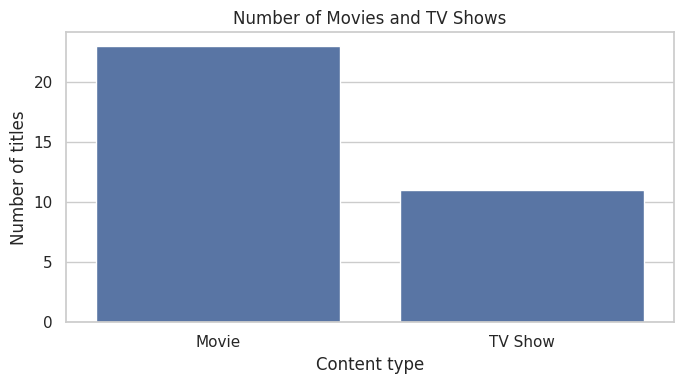

In [17]:
# 7. Visual style
sns.set_theme(style="whitegrid")

# Chart 1: Movies vs TV Shows
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="type", order=df["type"].value_counts().index)
plt.title("Number of Movies and TV Shows")
plt.xlabel("Content type")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.show()

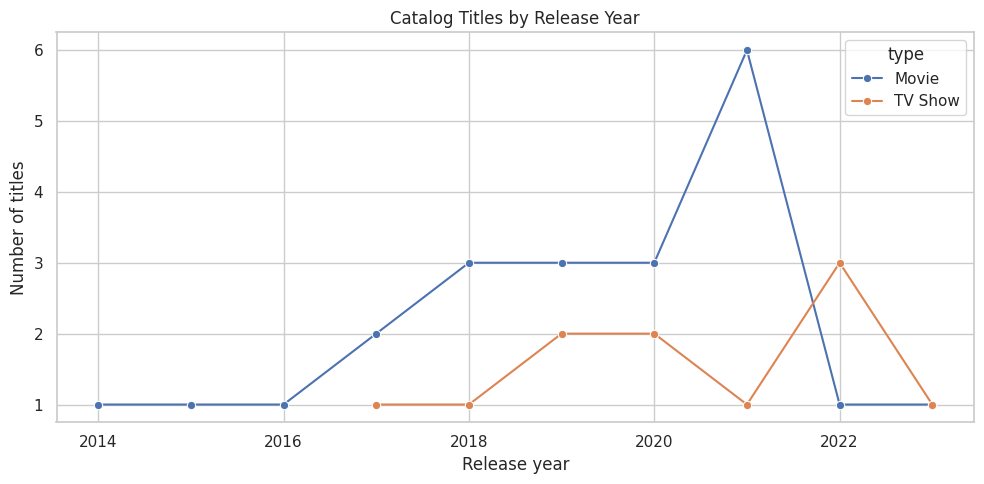

In [18]:
# Chart 2: Releases by year and type
year_type = (
    df.dropna(subset=["release_year"])
      .groupby(["release_year", "type"])
      .size()
      .reset_index(name="title_count")
)
plt.figure(figsize=(10, 5))
sns.lineplot(data=year_type, x="release_year", y="title_count", hue="type", marker="o")
plt.title("Catalog Titles by Release Year")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.show()

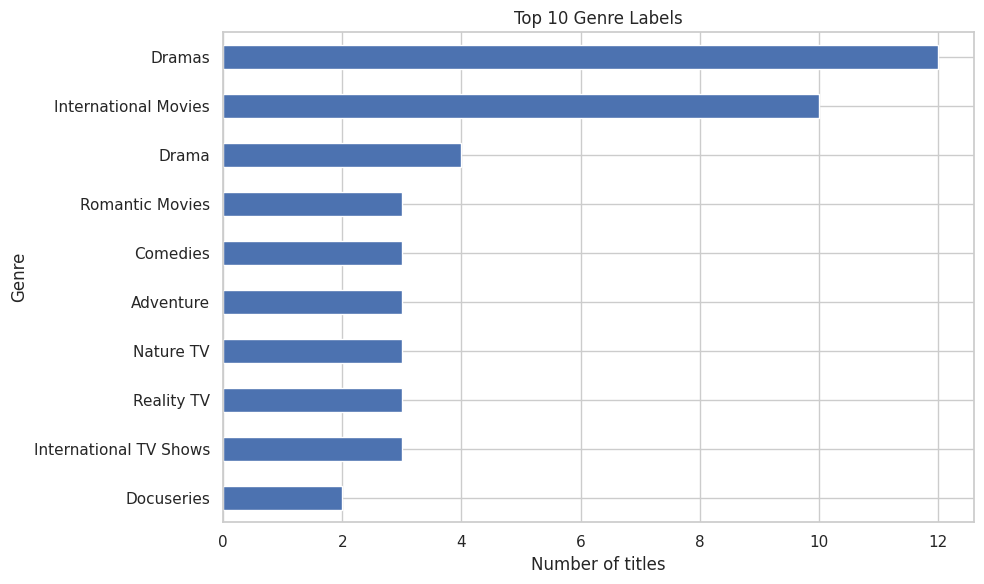

In [19]:
# Chart 3: Most common genres (a title can belong to multiple genres)
genre_df = df[df["listed_in"].notna()].copy()
genre_df["genre"] = genre_df["listed_in"].str.split(", ")
genre_df = genre_df.explode("genre")
top_genres = genre_df["genre"].value_counts().head(10).sort_values()
plt.figure(figsize=(10, 6))
top_genres.plot(kind="barh")
plt.title("Top 10 Genre Labels")
plt.xlabel("Number of titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

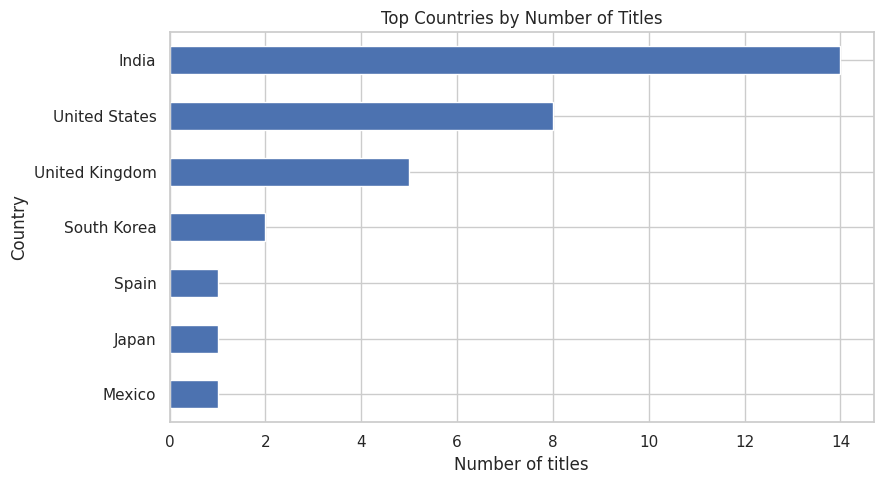

In [20]:
# Chart 4: Top countries (country cells can contain multiple countries)
country_df = df[df["country"].ne("Not specified")].copy()
country_df["country_item"] = country_df["country"].str.split(", ")
country_df = country_df.explode("country_item")
top_countries = country_df["country_item"].value_counts().head(10).sort_values()
plt.figure(figsize=(9, 5))
top_countries.plot(kind="barh")
plt.title("Top Countries by Number of Titles")
plt.xlabel("Number of titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

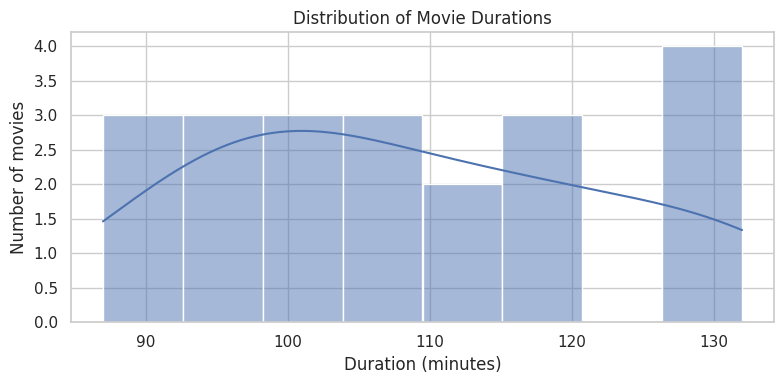

In [21]:
# Chart 5: Movie duration distribution
movie_plot = df[
    (df["type"] == "Movie") &
    (df["duration_unit"] == "minutes") &
    (df["duration_value"].notna())
]
plt.figure(figsize=(8, 4))
sns.histplot(data=movie_plot, x="duration_value", bins=8, kde=True)
plt.title("Distribution of Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of movies")
plt.tight_layout()
plt.show()

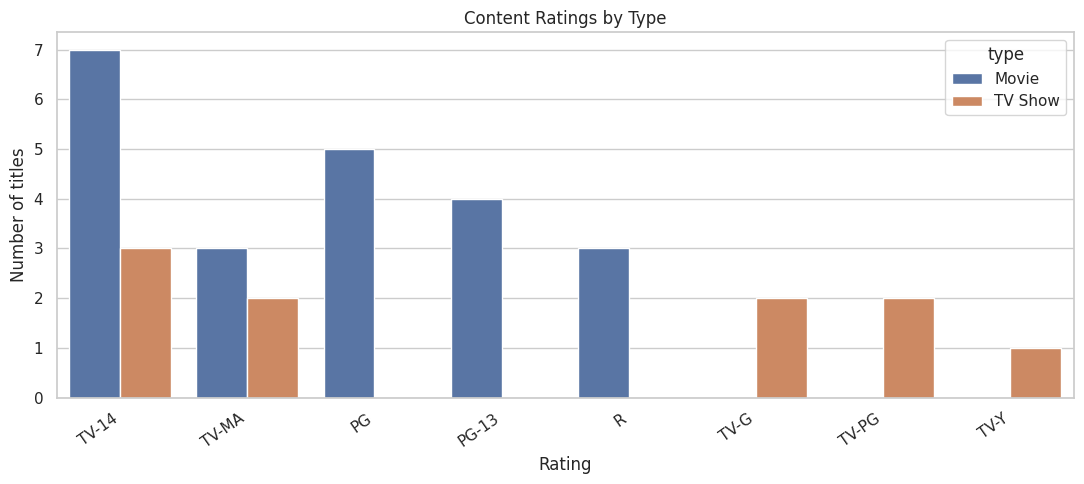

In [22]:
# Chart 6: Ratings by content type
rating_plot = df[df["rating"] != "Not specified"]
plt.figure(figsize=(11, 5))
sns.countplot(data=rating_plot, x="rating", hue="type",
              order=rating_plot["rating"].value_counts().index)
plt.title("Content Ratings by Type")
plt.xlabel("Rating")
plt.ylabel("Number of titles")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

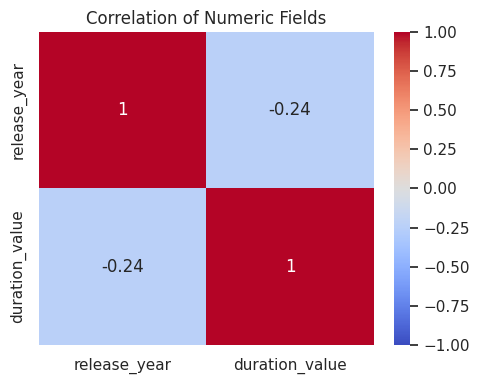

In [23]:
# Chart 7: Correlation heatmap for numeric columns
numeric_df = df[["release_year", "duration_value"]].dropna()
if len(numeric_df) >= 2:
    plt.figure(figsize=(5, 4))
    sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
    plt.title("Correlation of Numeric Fields")
    plt.tight_layout()
    plt.show()

In [24]:

# 8. Questions to answer in your final report
print("\nEDA complete. Write down 5-8 evidence-based findings from your charts.")



EDA complete. Write down 5-8 evidence-based findings from your charts.
